<img src="mlns.png" style="width: 200%; height: auto;">

# Solución MicroProyecto 1

## Generación de paleta de colores a partir de imágenes con técnicas de machine learning no supervisado

Una paleta de colores es un conjunto de tonos que se utilizan juntos para crear un efecto armonioso, coherente y atractivo en las representaciones visuales (diseño gráfico, cine, fotografía, pintura, etc.), así como para transmitir mensajes y generar emociones determinados, de acuerdo con la intencionalidad del autor de la obra.

En un contexto de amplia demanda de herramientas que puedan asistir a diseñadores gráficos, directores de arte, pintores y creadores de contenido, entre otros, para la selección rápida y adecuada de los colores apropiados para sus obras, una aplicación para configurar paletas de colores a partir de imágenes sería de mucha utilidad. 

El problema central radica en desarrollar un método automatizado que pueda generar una paleta coherente y estéticamente atractiva partiendo de los colores identificados en una imagen. Esto implica no solo reconocer tonos dominantes, sino también comprender la relación existente al interior de la gama cromática empleada para crear combinaciones visuales agradables y funcionales. Abordar este problema se traduciría en varias ventajas:

* Eficiencia en el proceso creativo, al liberar tiempo que los autores podrían emplear en otros aspectos estratégicos de sus proyectos.

* Consistencia interna en los diseños, manteniendo una identidad visual constante en diferentes aplicaciones y proyectos.

* Facilidad de uso y recurso de aprendizaje para personas con menos experiencia en diseño, fomentando la creatividad en diversos campos.

* Optimización de la calidad y del impacto de la comunicación visual. 

Una vía para lograr una herramienta como esta es utilizar técnicas de machine learning no supervisado sobre imágenes para visualizar la distribución de los colores dominantes presentes en estas y generar, de manera automática, modelos de paletas de colores. En esta primera aproximación el método va a permitir identificar los colores dominantes en una imagen para construir un muestrario por similitud de píxeles, lo cual puede ser muy útil para estudios de marketing, psicología, medicina, arte, ambiente, entre otros. Por ejemplo, se podrían extraer los colores de las diferentes superficies de la Tierra en una imagen satelital para estudiar la distribución de la vegetación o de la contaminación.

**A. Objetivo.**

Desarrollar un método, basado en técnicas de agrupación, que permita extraer los tonos dominantes de una imagen y generar un muestrario de los colores representativos presentes en esta. 

**B. Conjunto de datos.**

Los datos están asociados con imágenes de obras de arte. Pueden ser descargados a partir de este
 enlace
.

**C. Actividades para realizar.**

1. Recopilación de las imágenes a partir del repositorio. La idea es seleccionar un conjunto diverso de muestras en diferentes estilos artísticos (varios pintores). Se recomienda seleccionar entre 6 y 10 imágenes.

2. Preparación de las imágenes para el entrenamiento y prueba del modelo. Para este paso construir un pipeline que integre las transformaciones que se consideren adecuadas.

3. Desarrollo del modelo de agrupación para identificar los colores dominantes en una imagen.

4. Transformación de los grupos de colores identificados en un muestrario representativo. Adicionalmente, se debería mostrar la distribución de los colores de la imagen en un espacio de dos dimensiones utilizando una técnica de reducción de la dimensionalidad.

**D. Consideraciones.**

Un diagrama general del método que se quiere desarrollar se muestra en la siguiente la Fig. 1.


El algoritmo de agrupación a utilizar queda a consideración de cada grupo, pero es importante justificar la elección.

Para la visualización de la distribución de colores seleccionar un método como t-SNE.


# SOLUCIÓN

## 1.Importación de librerías requeridas 

Iniciaremos con la importación de librerías `numpy`, `os` y `cv2` para la carga y procesamiento de las imágenes, asi como de la librería `scikit_learn` para la implementación de los algoritmos de agrupación y la librería `matplot` para visualizar las imagenes resultantes:

In [1]:
import numpy as np
import pandas as pd
import os
import cv2
import glob
import random
import matplotlib.pyplot as plt
from IPython.display import display, Markdown

from sklearn.cluster import KMeans, MeanShift, estimate_bandwidth
from sklearn.metrics import silhouette_score
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import FunctionTransformer
from sklearn.manifold import TSNE

## 2. Carga de datos

Se definira el directorio raíz `root_path`, la lista de imágenes de imagenes `img_files` y una lista de extensiones válidas:

In [2]:
# Definir el directorio donde están las imágenes
root_path = r"C:\Users\acardenasm\Imagenes"
# Extensiones de imágenes permitidas
extensiones_validas = ("*.jpg", "*.jpeg", "*.png", "*.bmp", "*.webp")

### Recopilación de imágenes 

Se seleccionaron 32 imágenes pertenecientes a diferentes estilos artísticos, como cubismo, realismo y renacimiento. Asimismo, se incluyeron imágenes con variaciones en color, textura, formas y niveles de complejidad visual. La selección también estuvo influenciada por preferencias personales, priorizando imágenes con colores llamativos y representaciones de animales, debido a su atractivo visual e interés particular. Sin embargo, para evitar que la elección final de las imágenes analizadas dependiera de un criterio manual (lo cual introduciría un sesgo de selección hacia obras "convenientes" para el análisis), se utiliza `random.SystemRandom()` para elegir aleatoriamente 10 de las 32 imágenes disponibles cada vez que se ejecuta el notebook. Esto demuestra que el método generaliza a distintas combinaciones de obras y no depende de una muestra particular escogida a mano.

### Preparación de los datos

Se definio la  función `cargar_imagen()`  para la carga de imágenes y se definieron  las funciones que nos permitiran preparar los datos para la creación y ejecución del pipeline. 

* **DECISIONES TOMADAS**:

**1.Creación de la función cargar_imagen:** Se cargan las imágenes usando OpenCV, que las lee inicialmente en formato BGR, por lo que se convierten a RGB para que los colores se interpreten correctamente en la visualización y en la paleta final. Además, se incluye una validación que lanza un FileNotFoundError si la imagen no puede cargarse, evitando errores confusos más adelante en el pipeline. La selección aleatoria del subconjunto de imágenes (mediante random.SystemRandom) se realiza de forma independiente a esta función, garantizando que cada ejecución del notebook trabaje con una muestra distinta del conjunto total.


In [3]:
# Función para descargar la imágen y convertirla a RGB
def cargar_imagen(ruta):
    """
    Cargar una imágen desde el disco usando OpenCv y la convierte de BGR (formato nativo de OpenCv) a RGB (formato estándar para visualización 
    y para que los colores de la paleta se interpreten correctamente
    """
    img_bgr = cv2.imread(ruta)        
    # Validación del la extensión de la imágen
    if img_bgr is None:
        raise FileNotFoundError (f"No se pudo cargar la imágen: {ruta} porque extension no encontrada")
    # Convertir la imagen de BGR a RGB 
    img_rgb = cv2.cvtColor(img_bgr, cv2.COLOR_BGR2RGB)
    return img_rgb
# Recolectar automáticamente las rutas de las imágenes del directorio
image_paths = []

for ext in extensiones_validas:
    image_paths.extend(glob.glob(os.path.join(root_path, ext)))
image_paths = sorted(image_paths)
print (f"Se encontraron {len(image_paths)} imágenes en {root_path}")
# Seleccionar aleatoriamente del conjunto total únicamente 10 imágnes
n_seleccion = 10
if len(image_paths) > n_seleccion:
    generador = random.SystemRandom()
    image_paths = generador.sample(image_paths, n_seleccion)
else:
    print(f"El directorio tiene menos imágenes que {n_seleccion}; se usarán todas")

# Reordenar para visualización consistente
image_paths = sorted(image_paths)
print(f"Se seleccionaran aleatoriamente {len(image_paths)} imágenes")
# Cargar todas la imágenes en la lista
imagenes = []
nombres = []

for path in image_paths:
    img = cargar_imagen(path)
    imagenes.append(img)
    nombres.append(os.path.basename(path))
print(f"se cargaron {len(imagenes)} imágenes correctamente")   

Se encontraron 32 imágenes en C:\Users\acardenasm\Imagenes
Se seleccionaran aleatoriamente 10 imágenes
se cargaron 10 imágenes correctamente


Con el objetivo de lograr estetica visual y una fácil identificación del estilo de las imágenes, elaboramos un direccionario que asociada el nombre de la imágenes con el estilo.

In [4]:
# Diccionario con los 27 estilos artísticos 
estilos_arte = {
    "abstract_expressionism": "Imagen de estilo Expresionismo Abstracto.",
    "action_painting": "Imagen de estilo Action Painting.",
    "analytical_cubism": "Imagen de estilo Cubismo Analítico.",
    "art_nouveau_modern": "Imagen de estilo Art Nouveau / Modernismo.",
    "baroque": "Imagen de estilo Barroco.",
    "color_field_painting": "Imagen con estilo Color Field Painting.",
    "contemporary_realism": "Imagen de estilo Realismo Contemporáneo.",
    "cubism": "Imagen de estilo Cubista.",
    "early_renaissance": "Imagen de estilo Renacimiento Temprano.",
    "expressionism": "Imagen de estilo Expresionismo.",
    "fauvism": "Imagen de estilo Fauvista.",
    "high_renaissance": "Imagen de estilo Alto Renacimiento.",
    "impressionism": "Imagen de estilo Impresionista.",
    "mannerism_late_renaiss": "Imagen de estilo Manierismo / Renacimiento Tardío.",
    "minimalism": "Imagen de estilo Minimalista.",
    "naive_art_primitivism": "Imagen de estilo Arte Naif / Primitivismo.",
    "new_realism": "Imagen de estilo Nuevo Realismo.",
    "northern_renaissance": "Imagen de estilo Renacimiento Nórdico.",
    "pointillism": "Imagen de estilo Puntillista.",
    "pop_art": "Imagen de estilo Pop Art.",
    "post_impressionism": "Imagen de estilo Postimpresionista.",
    "realism": "Imagen de estilo Realista.",
    "rococo": "Imagen de estilo Rococó.",
    "romanticism": "Imagen de estilo Romanticismo.",
    "symbolism": "Imagen de estilo Simbolismo.",
    "synthetic_cubism": "Imagen de estilo Cubismo Sintético.",
    "ukiyo_e": "Imagen de estilo Ukiyo-e."
}

# Cómo tenemos estilos con palabras compuestas, por ejemplo, "analytical_cubism" y "cubism", ordenamos las claves por longitud
# de la más larga a la más corta
claves_ordenadas = sorted(estilos_arte.keys(), key=len, reverse=True)

# Procesamos las imágenes y convertimos el nombre en minúscula
def obtener_texto_estilo(nombre_archivo):
    nombre_minuscula = nombre_archivo.lower()

    # Si una imágene no se encuentra dentro de un estilo entonces se asigna mensaje generico
    texto = "Imágen seleccionada para el análisis"

    # Buscamos coincidencia usando el orden seguro
    for clave in claves_ordenadas:
        if clave in nombre_minuscula:
            texto = estilos_arte[clave]
            break 

    return texto

Se organizaron las imágenes en una cuadricula que permite visualizarlasen 3 columnas de tamaño 15 y filas de tamaño 5 cada una y se adiciona el nombre de la imágen con el correspondiente estilo al que pertenece.

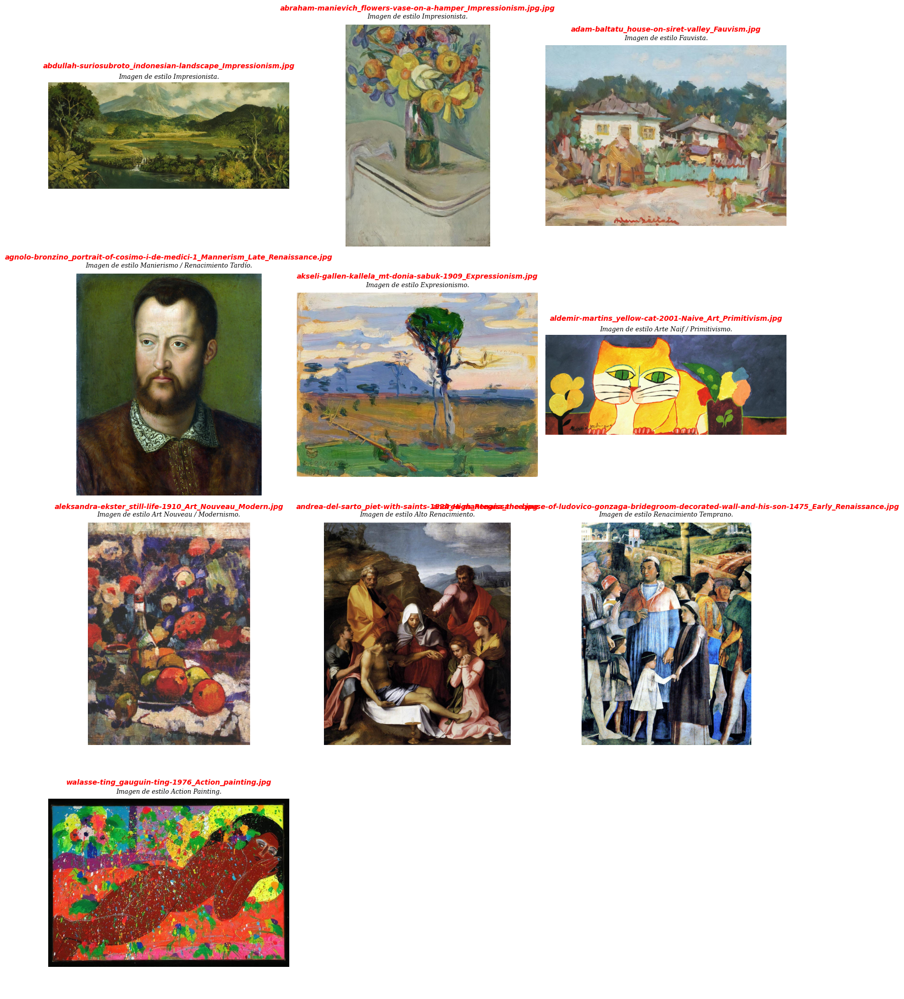

In [5]:
# Visualizar las imágenes seleccionadas
n = len(imagenes)
cols =3 # Decidimos 3 columnas para que la imágen sea lo sufiente clara
rows = (n + cols - 1) // cols

# creamos una figura en bloques para la visualización de la imágen
fig, axes = plt.subplots(rows, cols, figsize=(15, 5 * rows))
axes = axes.flatten()

# Recorrer cada imágen para obtener el texto
for i, (img, nombre) in enumerate(zip(imagenes, nombres)):
    texto = obtener_texto_estilo(nombre)
    axes[i].imshow(img)
    axes[i].set_title(nombre, color="red", fontsize=10, fontstyle="italic", fontweight="bold", pad=20)
    axes[i].text(0.5, 1.02, texto, transform=axes[i].transAxes, ha="center", va="bottom", fontsize=9, fontstyle="italic", fontfamily="serif", wrap=True)  # <-- línea nueva
    axes[i].axis("off")

for j in range(i + 1, len(axes)):
    axes[j].axis("off")
plt.tight_layout()
plt.show()

* **DECISIONES TOMADAS**:

**2.Creación de la función **redimensionar_imagen**:**  Antes de aplanar los píxeles, cada imagen se redimensiona a un tamaño fijo (128×128) mediante `cv2.resize`, con el fin de reducir el costo computacional de los algoritmos de agrupamiento como K-Means y MeanShift, y de la reducción de dimensionalidad con t-SNE, ya que todos ellos escalan mal con el número de píxeles procesados. Al aplicarse antes de cualquier algoritmo, esta función es independiente del modelo de agrupamiento utilizado.

**3.Creación de la función aplanar_imagen(flatten):** Las imagenes se representa como una matriz de forma (alto, ancho, 3), donde  cada celda contiene los valores RGB de un píxel. Como los algoritmos de agrupamiento de scikit-learn (K-Means, MeanShift, entre otros) solo pueden procesar datos en forma de tabla (una lista de muestras con sus características), esta función convierte la imagen a una tabla de forma (n_píxeles, 3), donde cada fila es un píxel y sus columnas son sus valores R, G y B. En este proceso se descarta intencionalmente la posición (x, y) de cada píxel, ya que el objetivo es agrupar los píxeles por similitud de color y no por su ubicación dentro de la imagen. 

**4.Creación de la función escalar pixeles:** Con la salida de la función de aplanamiento, se escalan los valores RGB del rango [0, 255] al rango [0, 1]. Esto es importante porque el algoritmo de agrupamiento utiliza distancias para asignar cada píxel a su grupo correspondiente, por lo que trabajar en una escala numérica consistente facilita y estabiliza ese cálculo.



In [6]:
#Función para redimensionar la imagen 
def redimensionar_imagen(imagen, tamaño=(128, 128)):
    """
    Redimensiona la imagen para reducir el costo computacional
    de K-Means y t-SNE.
    """
    return cv2.resize(imagen,tamaño,interpolation=cv2.INTER_AREA)

In [7]:
# Función para "aplanar" la imágen en una lista de píxeles
def aplanar_imagen(img):
    """
    Convierte la imágen de forma (alto, ancho, 3) a una tabla de forma (n_pixeles, 3), donde cada fila es un píxel con sus valores 
    [R,G,B]. Aquí se pierde la información espacial (x,y) de cada píxel intencionalmente: porque para efectos de la información que
    el algoritmo recibe solo es importante el color, no la posición
    """
    pixeles = img.reshape(-1,3)
    return pixeles 

In [8]:
# Función para escalar los valors de los píxeles
def escalar_pixeles(pixeles):
    """
    Escala los valores RGB, originalmente en el rango [0, 255], al rango [0, 1]. Esto permite aplicar el algoritmo usando distancias
    euclidianas con una escala numérica consistente.
    """
    return pixeles.astype(np.float32) / 255.0

Se construye un Pipeline para preparar los datos con las funciones **Redimensionar_imagen,** **aplanar_imagen** y **escalar_pixeles**. Este permitirá ejecutar las transformaciones de las imágenes en el orden correcto y garantizará que todas sean procesadas bajo las mismas condiciones. Además, las funciones definidas podrán reutilizarse con otras imágenes o proyectos, evitando tener que implementarlas nuevamente y reduciendo posibles errores durante el procesamiento.

In [9]:
# Definición del pipeline empleando la herramienta de librería sklearn
pipeline_preparacion=Pipeline([
    ("Redimensionar_imagen", FunctionTransformer(redimensionar_imagen)),
    ("aplanar_imagen", FunctionTransformer(aplanar_imagen)),
    ("escalar_pixeles", FunctionTransformer(escalar_pixeles))
])

pixeles_imagen= [pipeline_preparacion.transform(imagen)
                for imagen in imagenes]

for nombre, pixeles in zip(nombres, pixeles_imagen):
    print(f"{nombre:<25}: | {pixeles.shape} | pixeles RGB preparados")

abdullah-suriosubroto_indonesian-landscape_Impressionism.jpg: | (16384, 3) | pixeles RGB preparados
abraham-manievich_flowers-vase-on-a-hamper_Impressionism.jpg.jpg: | (16384, 3) | pixeles RGB preparados
adam-baltatu_house-on-siret-valley_Fauvism.jpg: | (16384, 3) | pixeles RGB preparados
agnolo-bronzino_portrait-of-cosimo-i-de-medici-1_Mannerism_Late_Renaissance.jpg: | (16384, 3) | pixeles RGB preparados
akseli-gallen-kallela_mt-donia-sabuk-1909_Expressionism.jpg: | (16384, 3) | pixeles RGB preparados
aldemir-martins_yellow-cat-2001-Naive_Art_Primitivism.jpg: | (16384, 3) | pixeles RGB preparados
aleksandra-ekster_still-life-1910_Art_Nouveau_Modern.jpg: | (16384, 3) | pixeles RGB preparados
andrea-del-sarto_piet-with-saints-1524_High_Renaissance.jpg: | (16384, 3) | pixeles RGB preparados
andrea-mantegna_the-house-of-ludovico-gonzaga-bridegroom-decorated-wall-and-his-son-1475_Early_Renaissance.jpg: | (16384, 3) | pixeles RGB preparados
walasse-ting_gauguin-ting-1976_Action_painting.jpg

## Desarrollo del modelo de agrupación

### Implementación de modelos de agrupación seleccionados: K-Means y MeansShift

* **DECISIONES TOMADAS**
  
En este punto se implementan y comparan 2 algoritmos de agrupamiento no supervisado: **K-Means** y **MeanShift**

Se selecciona **k-Means** debido a que prmite controlar el número de colores de la paleta mediante la definición previa del número de grupos *k*,se utilizan criterios de evaluación como  coeficiente de la silueta y el método del codo, los cuales permiten identificar una partición que represente adecuadamente la distribución de colores presente en cada imagen. Adicionalmente se implementa **MeanShift** para comparar, y se utiliza ya que a diferencia de K-means, este algoritmo no requiere especificar previamente el número de grupos porque identifica automáticamente los cluster a partir de la densidad de los datos, esto resulta particularmente útil para analizar imágenes cuya distribución de colores puede variar significativamente, permitiendo evaluar si una estrategia basada en densidad logra representar de manera más precisa los colores dominantes de cada obra.  

La comparación entre estos dos enfoques permite analizar las ventajas y limitaciones de cada algoritmo en la generación automática de paletas de colores, considerando aspectos como la calidad del agrupamiento, la interpretabilidad de los resultados y la capacidad para adaptarse a diferentes estilos artísticos.

### Implementación de K-means

* **DECISIONES TOMADAS**
  
Se define un rango inicial de busqueda entre 3 y 10 grupos con el próposito de identificar la configuración que produce la mejor calidad de agrupamiento mediante el método del codo y el coeficiente de silueta. Este intervalo es lo sufientemente amplio para capturar imágenes con diferentes niveles de complejidad en el color, sin generar fragmentación excesiva de los colores presentes en la misma. Además, limitar el rango de busqueda permite mantener tiempos de ejecución razonables en este proceso.

* **Nota sobre el límite inferior (k=3):** inicialmente se evaluó un rango desde k=2, pero se observó que el coeficiente de silueta tiende a favorecer sistemáticamente particiones muy simples (como separar la imagen en solo "tonos claros" vs. "tonos oscuros"), ya que esta métrica premia grupos grandes y muy bien separados por encima de particiones más finas y visualmente más ricas. Esto llevaba a que, en la mayoría de las imágenes, se seleccionara k=2 como "óptimo" aunque la paleta resultante fuera poco representativa de la diversidad cromática real de la obra. Por esta razón, se decidió establecer k=3 como límite inferior del rango de búsqueda, garantizando un mínimo de granularidad en la paleta generada sin descartar la validación cuantitativa mediante el coeficiente de silueta.

In [10]:
# Función para la definición del modelo kmeans
def k_means_model(numero_cluster):
    """
    Se utilizara la función k_means_model de forma independiente con el propósito de poder probar diferentes valores de k,
    sin duplicar instrucciones adicionalmente se agregan parámetros como random_state para controlar la inicialización aleatoria aleatorias
    """
    return KMeans(n_clusters=numero_cluster, random_state=42, n_init=20)

In [11]:
# Función para entrenar y evaluar múltiples modelos K-Means
def evaluar_kmeans_model(fabrica_modelos, image, min_particion=3, max_particion=10):
    """
    Se utiliza esta función para entrenar y evaluar múltiples modelos K-Means considerando diferentes valores de k.
    """
    resultados=[]
    n_pixeles=len(image)
    max_particion=min(max_particion,n_pixeles-1)

    for k in range(min_particion,max_particion+1):
        modelo=fabrica_modelos(k)
        etiquetas=modelo.fit_predict(image)

        silueta=silhouette_score(image,etiquetas,sample_size=min(3000, n_pixeles-1),random_state=42)

        resultados.append({
            "k":k,
            "modelo":modelo,
            "inercia":modelo.inertia_,
            "silueta":silueta,
            "etiquetas":etiquetas,
            "centroides":modelo.cluster_centers_
        })

    return pd.DataFrame(resultados)

Se desarrolla una prueba para ejecutar, evaluar y visualizar de forma compacta los resutados del algoritmo K-Means aplicado a la primer imágen del conjunto total probando con diferentes valores de K tanto para las métricas codo y silueta.

In [12]:
# Imprimir el "shape" de los píxeles de la primera imágen
print(pixeles_imagen[0].shape)

# Evaluar el modelo con la primera imágen
resultados_k=evaluar_kmeans_model(k_means_model,pixeles_imagen[0])

# Generar la tabla de resultados
resultados_k[["k","silueta","inercia"]]

(16384, 3)


,k,silueta,inercia
0,3,0.543055,225.044159
1,4,0.487144,156.697159
2,5,0.473542,107.458908
3,6,0.433623,88.246063
4,7,0.435663,71.963684
5,8,0.420564,60.983440
6,9,0.383699,54.580429
7,10,0.373955,48.471348


Se selecciona y muestra en pantalla de forma automática el mejor modelo de K-Means basándose en la métrica de la silueta.

In [13]:
mejor_modelo=resultados_k.loc[resultados_k["silueta"].idxmax()]

print(f"Imagen:{nombres[0]}")
print(f"Mejor k:{mejor_modelo['k']}")
print(f"Silueta:{mejor_modelo['silueta']:.3f}")

Imagen:abdullah-suriosubroto_indonesian-landscape_Impressionism.jpg
Mejor k:3
Silueta:0.543


* **DECISIONES TOMADAS**

Se automatiza la selección del número óptimo de clústeres (k) para el algoritmo K-Means mediante la función **mejor_numero_cluster**. Esta recibe como argumento el DataFrame con las métricas de rendimiento calculadas previamente y, utilizando el método `idxmax()`, localiza y extrae de forma automática la fila correspondiente al valor más alto del coeficiente de silueta.
Aunque se calculan y comparan ambas métricas: **el método del codo (Elbow Method)** y el **coeficiente de silueta**, se selecciona el coeficiente de silueta como criterio de decisión, ya que este produce un valor numérico exacto entre -1 y 1 que mide simultáneamente la cohesión interna y la separación entre clústeres, lo cual lo hace más apropiado y objetivo para determinar el valor óptimo de k que el método del codo, que depende de una interpretación visual de la curva de inercia. 

In [14]:
# Definir el mejor cluster
def mejor_numero_cluster(resultados):
    """
    Define el mejor cluster
    """
    return resultados.loc[resultados["silueta"].idxmax()]

En la función **analizar_imagen_kmeans** se orquestan las funciones para procesar los píxeles de una imagen para extraer automáticamente su paleta de colores principales utilizando el algoritmo de agrupamiento de K-Means, ordenándolos de mayor a menor importancia. Se evalua el modelo con diferentes k, se selecciona el mejor modelo y se extrae los centroides y las etiquetas. Esta función retorna los resultados, el mejor modelo, colores, y porcentajes de cada color. 

In [15]:
# Orquestar los pasos anteriores para analizar la imágen
def analizar_imagen_kmeans(pixeles, nombre):
    """
    Armar la paleta de colores de la imagen y ordena de mayor a menor importancia en base con el resultado matemático que dio el
    algoritmo K-Means
    """
    # Evaluar el algoritmo sobre los píxeles de la imagen con varias configuraciones
    resultados=evaluar_kmeans_model(k_means_model,pixeles)

    # Analizar los resultados del paso anterior y aplicar el criterio matemático para elegir la cntidad ideal de colores para la paleta
    # Devuelve el modelo ganador
    mejor_modelo=mejor_numero_cluster(resultados)
    
    # Extraer los datos del mejor modelo para enviar a la función generar paleta
    modelo = mejor_modelo["modelo"]
    etiquetas = mejor_modelo["etiquetas"]

    colores, porcentajes, colores_hex = generar_paleta(mejor_modelo["centroides"],etiquetas)
    return {
        "nombre": nombre,
        "resultados": resultados,
        "modelo": modelo,
        "etiquetas": etiquetas,
        "colores": colores,
        "porcentajes": porcentajes,
        "colores_hex": colores_hex}

### Implementación de MeanShift

A diferencia de K-Means, MeanShift no requiere fijar previamente el número de clústeres: estima automáticamente un ancho de banda (bandwidth) a partir de una muestra de píxeles y agrupa los puntos según la densidad local. Esto lo hace útil para explorar cuántos colores dominantes emergen naturalmente de una imagen, aunque el número resultante no es controlable ni está validado por una métrica como el coeficiente de silueta

In [16]:
def analizar_meanshift(pixeles,nombre,quantile=0.2,n_samples=100):
    n_samples=min(n_samples,len(pixeles))
    #Estima el ancho de banda usando una muestra de píxeles
    bandwidth=estimate_bandwidth(pixeles,quantile=quantile,n_samples=n_samples,random_state=42)
    #Para evitar un bandwidth inválido
    bandwidth=max(bandwidth,0.01)
    #Creamos el modelo
    modelo_mean=MeanShift(bandwidth=bandwidth,bin_seeding=True,cluster_all=True)
    etiquetas=modelo_mean.fit_predict(pixeles)
    centroides=modelo_mean.cluster_centers_
    #Generamos la paleta de colores
    colores,porcentajes,colores_hex=generar_paleta(centroides,etiquetas)
    return {
        "nombre":nombre,
        "bandwidth":bandwidth,
        "modelo":modelo_mean,
        "etiquetas":etiquetas,
        "centroides":centroides,
        "colores":colores,
        "porcentajes":porcentajes,
        "colores_hex":colores_hex
    }

## 4. Transformación de los grupos de colores identificados en un muestrario representativo.

A través de la función **generar_paleta** se genera la paleta de colores recibiendo los **centroides** y las **etiquetas** como resultado del análisis de los píxeles de cada imagen, es decir, el muestrario representtivo se contruye a partir del resultado del modelo aplicado a cada imagen. Adicionalmente, se realiza la conversión del formato de color RGB al formato hexadecimal, con el fin de mostrar el código de cada color de forma legible y estándar en la visualización generada con la librería matplotlib. 

In [17]:
# Generar la paleta de colobres 
def generar_paleta(centroides,etiquetas):
    """
    Función que recibe los centroides y etiquetas para generar la paleta de colores
    """
    # Contar cuántas veces aparece cada número (etiqueta) en la lista de etiquetas
    conteos=np.bincount(etiquetas)
    # Transormar el conteo en porcentaje(%)
    porcentajes=conteos/len(etiquetas)*100
    # Guardar la posición de los colores más importantes
    orden=np.argsort(porcentajes)[::-1]
    # Reordena los centroides por predominancia, los convierte de [0,1] a RGB [0,255] y asegura que sus valores sean enteros válidos
    colores=np.clip(centroides[orden]*255,0,255).astype(int)
    # Reordenar los porcentajes
    porcentajes=porcentajes[orden]
    #Aca convertimos los valores R,G,B a digitos exadecimales
    colores_hex=["#{:02X}{:02X}{:02X}".format(color[0],color[1],color[2])
        for color in colores
    ]

    return colores,porcentajes,colores_hex

* **DECISIONES TOMADAS:**

Se crea la función **reconstruir_imagen_segmentada**  para visualizar de forma directa el resultado del agrupamiento sobre la imagen original, reconstruyendo una versión en la que cada píxel es reemplazado por el color del centroide del clúster al que fue asignado. Para esto, se utiliza el arreglo etiquetas (que indica a qué clúster pertenece cada píxel), obteniendo así, para cada uno de los píxeles, el color promedio de su grupo correspondiente en lugar de su color original. Dado que los centroides se calculan en la escala normalizada [0,1] (la misma usada por escalar_pixeles), es necesario multiplicar por 255 y aplicar `np.clip` para evitar valores fuera de rango antes de convertir a enteros de 8 bits (uint8), formato requerido por matplotlib para representar imágenes correctamente. Finalmente, dado que el proceso de agrupamiento trabaja sobre la tabla aplanada de píxeles (n_píxeles, 3), se utiliza reshape para recuperar la estructura original de la imagen (alto, ancho, 3) y así poder visualizarla. *Esta reconstrucción es una herramienta útil para evaluar cualitativamente qué tan bien representa el modelo la estructura de color de la imagen original*

In [18]:
# Reconstruye la imagen reemplazando cada píxel por el color de su centroide
def reconstruir_imagen_segmentada(etiquetas, centroides, forma=(128,128,3)):
    """
    Permite visualizar la segmentación generada por el modelo.
    """
    pixeles_segmentados=np.clip(centroides[etiquetas]*255,0,255).astype(np.uint8)
    return pixeles_segmentados.reshape(forma)

Se ejecuta el análisis completo y se muestran los resultados finales para la primera imagen que fue seleccionada 

In [19]:
# Ejecutar el análisis y guuardar los datos
resultado = analizar_imagen_kmeans(pixeles_imagen[0],nombres[0])

print(f"Imagen: {resultado['nombre']}")
print(f"Mejor k: {resultado['modelo'].n_clusters}")
print( f"Silueta: "
       f"{resultado['resultados']['silueta'].max():.3f}")
print(resultado["colores_hex"])

Imagen: abdullah-suriosubroto_indonesian-landscape_Impressionism.jpg
Mejor k: 3
Silueta: 0.543
['#363D1E', '#6E7130', '#AEAF80']


Se visualiza el comportamiento del algoritmo K-Means al probrar diferentes valores de K. 

In [20]:
# Graficar las métricas 
def graficar_metricas(resultados, nombre_imagen):
    """ 
    Función para la justificación visutal de la selcción del número especifico de colores y no otro
    """
    mejor_silueta=resultados.loc[resultados["silueta"].idxmax()]
    mejor_k_silueta=mejor_silueta["k"]
    
    fig,ax=plt.subplots(1,2,figsize=(12,4))

    ax[0].plot(resultados["k"],resultados["inercia"],marker="o",color="orange")
    ax[0].set_xlabel("Número de grupos (k)")
    ax[0].set_ylabel("Inercia")
    ax[0].set_title("Método del codo")
    ax[0].grid()

    ax[1].plot(resultados["k"],resultados["silueta"],marker="o",color="steelblue")
    ax[1].axvline(mejor_k_silueta,color="red",linestyle="--",label=f"Mejor k={mejor_k_silueta}")
    ax[1].set_xlabel("Número de grupos (k)")
    ax[1].set_ylabel("Coeficiente de silueta")
    ax[1].set_title("Método de silueta")
    ax[1].legend()
    ax[1].grid()

    fig.suptitle(f"Métricas de agrupamiento: {nombre_imagen}")
    plt.tight_layout()
    plt.show()

Se prueba la función en la primera imagén del dataset.

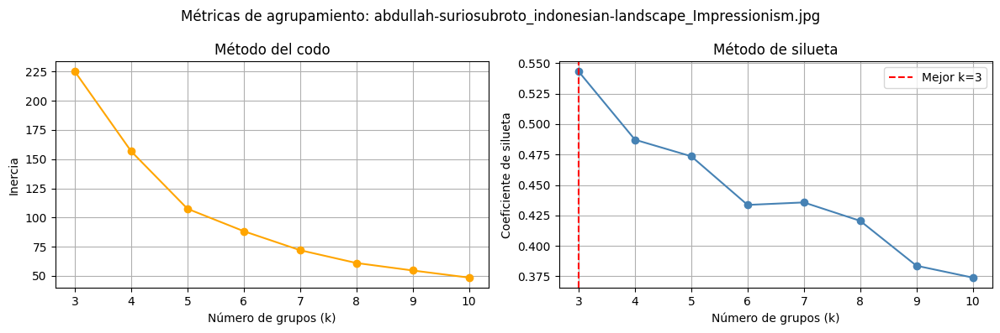

In [21]:
graficar_metricas(resultados_k,nombres[0])

Visualización gráfica del proyecto, cuyo objetivo es contrastar la imagen original con la paleta de colores generada, mostrando cada color como una barra vertical acompañada de su código hexadecimal y su porcentaje de presencia en la imagen. Adicionalmente, se muestra la imagen reconstruida, en la cual cada píxel es reemplazado por el color del centroide de su clúster correspondiente, permitiendo visualizar de forma directa qué tan bien la paleta representa la distribución de colores de la obra original.

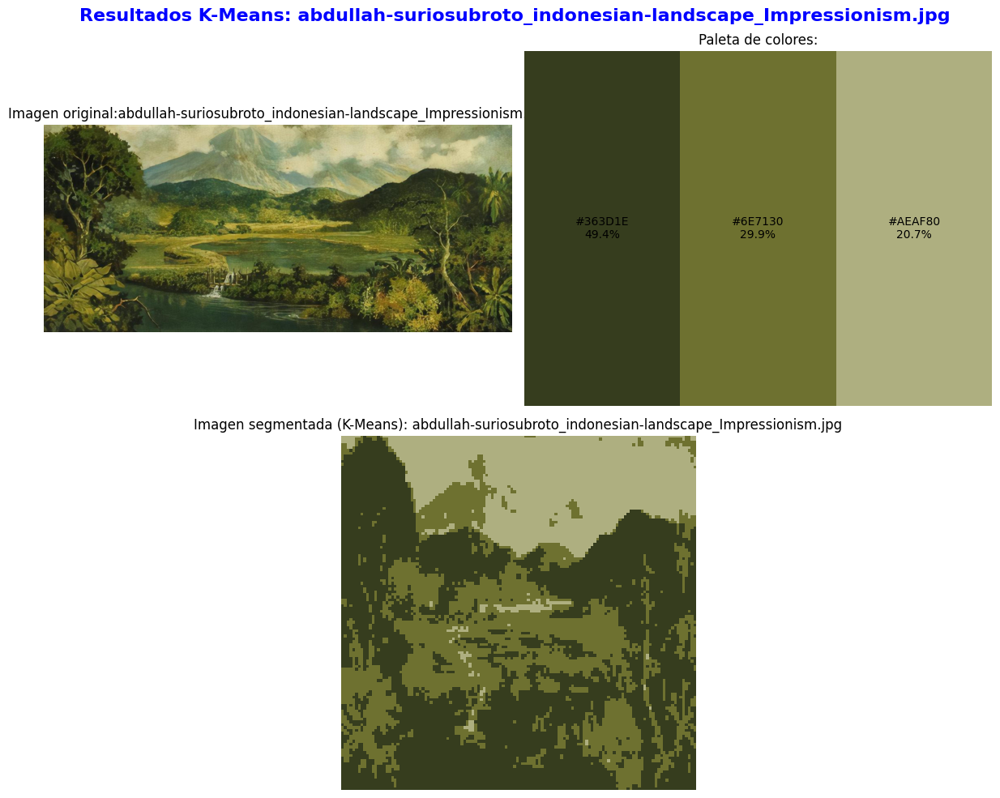

In [22]:
mejor_modelo=resultados_k.loc[resultados_k["silueta"].idxmax()]

colores,porcentajes,colores_hex=generar_paleta(mejor_modelo["centroides"],mejor_modelo["etiquetas"])
imagen_segmentada=reconstruir_imagen_segmentada(mejor_modelo["etiquetas"],mejor_modelo["centroides"])

fig=plt.figure(figsize=(12,10))
gs=fig.add_gridspec(2,4)

ax_original=fig.add_subplot(gs[0,0:2])
ax_paleta=fig.add_subplot(gs[0,2:4])
ax_segmentada=fig.add_subplot(gs[1,1:3])

fig.suptitle(f"Resultados K-Means: {nombres[0]} ", color="blue", fontsize=16, fontweight="bold")

ax_original.imshow(imagenes[0])
ax_original.axis("off")
ax_original.set_title(f"Imagen original:{nombres[0]}")

for indice,(color,porcentaje,color_hex) in enumerate(zip(colores,porcentajes,colores_hex)):
    ax_paleta.bar(indice,1,color=color/255,width=1)
    ax_paleta.text(indice,0.5,f"{color_hex}\n{porcentaje:.1f}%",ha="center",va="center",fontsize=10)
ax_paleta.set_xlim(-0.5,len(colores)-0.5)
ax_paleta.set_ylim(0,1)
ax_paleta.axis("off")
ax_paleta.set_title(f"Paleta de colores:")

ax_segmentada.imshow(imagen_segmentada)
ax_segmentada.axis("off")
ax_segmentada.set_title(f"Imagen segmentada (K-Means): {nombres[0]}")

plt.tight_layout()
plt.show()

## Reasultados Meanshift
Ahora vamor a implementar el modelo MeanShift, no necesita especificar el número de clústeres, pero sí necesita estimar una ventana:

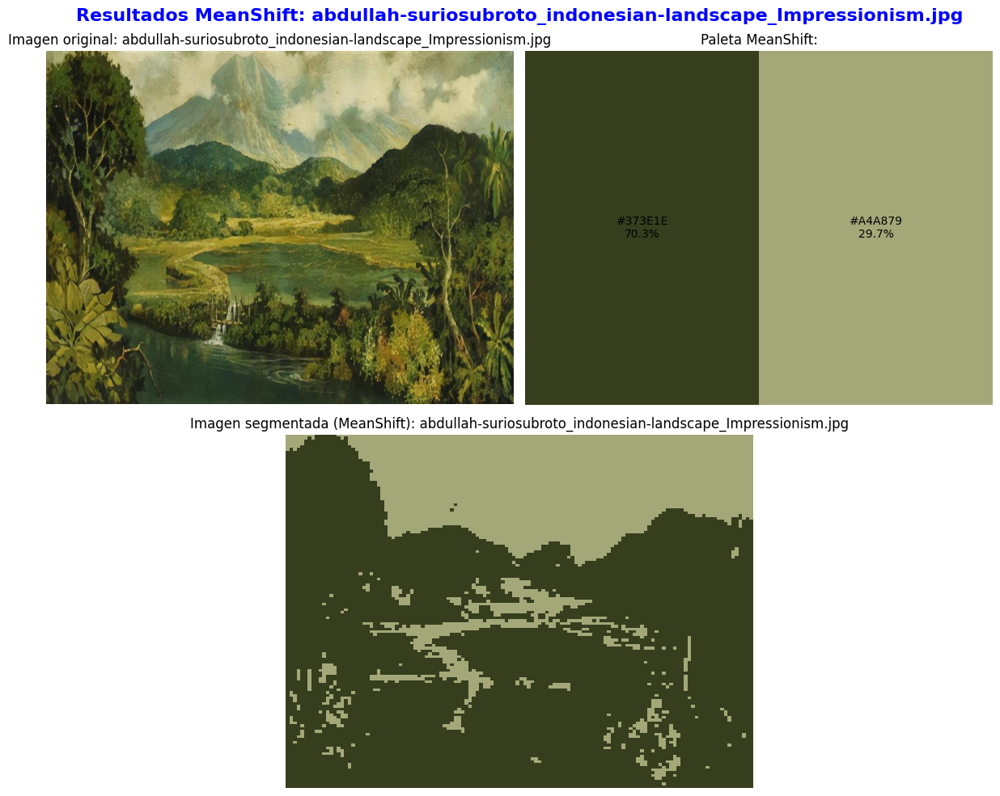

In [23]:
resultado_meanshift=analizar_meanshift(pixeles_imagen[0],nombres[0],quantile=0.2,n_samples=100)

# Extrae los datos de la paleta ya generados por MeanShift
colores=resultado_meanshift["colores"]
porcentajes=resultado_meanshift["porcentajes"]
colores_hex=resultado_meanshift["colores_hex"]
imagen_segmentada=reconstruir_imagen_segmentada(resultado_meanshift["etiquetas"],resultado_meanshift["centroides"])

fig=plt.figure(figsize=(12,10))
gs=fig.add_gridspec(2,4)

ax_original=fig.add_subplot(gs[0,0:2])
ax_paleta=fig.add_subplot(gs[0,2:4])
ax_segmentada=fig.add_subplot(gs[1,1:3])

fig.suptitle(f"Resultados MeanShift: {nombres[0]}", color="blue", fontsize=16, fontweight="bold")

# Muestra la imagen original
ax_original.imshow(imagenes[0],aspect="auto")
ax_original.axis("off")
ax_original.set_title(f"Imagen original: {nombres[0]}")

# Dibuja cada color de la paleta con su código y porcentaje
for posicion,(color,porcentaje,color_hex) in enumerate(zip(colores,porcentajes,colores_hex)):
    ax_paleta.bar(posicion,1,color=color/255,width=1)
    ax_paleta.text(posicion,0.5,f"{color_hex}\n{porcentaje:.1f}%",ha="center",va="center",fontsize=10)
ax_paleta.set_xlim(-0.5,len(colores)-0.5)
ax_paleta.set_ylim(0,1)
ax_paleta.axis("off")
ax_paleta.set_title(f"Paleta MeanShift:")

# Muestra la imagen reconstruida a partir de los centroides de MeanShift
ax_segmentada.imshow(imagen_segmentada,aspect="auto")
ax_segmentada.axis("off")
ax_segmentada.set_title(f"Imagen segmentada (MeanShift): {nombres[0]}")

plt.tight_layout()
plt.show()

#### Por qué usar K-means y no MeanShift?

Tanto K-Means como MeanShift asignan los píxeles a un grupo mediante la distancia respecto a un punto representativo (el centroide en K-Means, la moda de densidad en MeanShift), y en ambos casos es posible calcular qué porcentaje de píxeles pertenece a cada grupo para ordenar la paleta de colores. Sin embargo, existen varias razones por las que se eligió K-Means como algoritmo principal:

**1. Control explícito del número de colores** :En K-Means, el número de grupos (k) es un parámetro que se define explícitamente y que, en este proyecto, no se fija de manera arbitraria: se evaluaron distintos valores de k para cada imagen y se seleccionó aquel con el mejor coeficiente de silueta. En MeanShift, en cambio, el número de grupos no se define directamente, sino que es una consecuencia indirecta del ancho de banda (bandwidth) estimado automáticamente, sin un criterio de validación cuantitativo equivalente.

**2. Mayor control sobre la generación de paletas** El objetivo principal del proyecto es obtener una representación simplificada y visualmente útil de los colores dominantes de cada obra. K-Means permite controlar directamente el nivel de detalle de la paleta mediante el valor de k, mientras que MeanShift puede generar un número excesivo o insuficiente de colores dependiendo de la distribución de los datos. Esto facilita obtener paletas consistentes y comparables entre diferentes imágenes.

**3. Menor costo computacional** Las imágenes contienen miles de píxeles. K-Means posee una complejidad computacional relativamente baja y suele converger rápidamente, incluso con grandes volúmenes de datos. MeanShift, en cambio, realiza estimaciones de densidad alrededor de cada punto y requiere calcular múltiples distancias entre observaciones, lo que incrementa significativamente el tiempo de procesamiento. 

**4. Mayor estabilidad de los resultados** Cuando se utiliza una inicialización adecuada y múltiples ejecuciones (n_init), K-Means suele producir resultados estables. MeanShift es particularmente sensible a la estimación del parámetro bandwidth: pequeñas variaciones en este valor pueden producir cambios importantes en el número de grupos encontrados y, por consiguiente, en la paleta obtenida.

**5. Es una técnica ampliamente utilizada para segmentación por color** K-Means es uno de los algoritmos más empleados en tareas de reducción de colores, compresión de imágenes, segmentación de imágenes y extracción de colores dominantes. Su uso en este contexto está ampliamente documentado en la literatura de procesamiento digital de imágenes, lo que respalda metodológicamente su elección para este proyecto.

### Implementación de T-SNE
Con t-SNE se proyectan los píxeles de 3 dimensiones (R,G,B escalados a [0,1]) a 2 dimensiones, priorizando conservar que tan cerca estaban los puntos vecinos entre sí. El resultado es un gráfico de dispersión x.y donde se observa visualmente si los clústereses que encontró K-Means están bien seapados o se mezclan entre sí. La aplicación de t-SNE es computacionalmente costosa, ya que la literatura señala que evalua la similutd entre cada par de puntos de todo el conjunto de datos; por esta razón se utiliza una submuestra aleatoria de píxeles en lugar de la imagen completa. No se opta por la aplicación de PCA previa a t-SNE porque estamos trabajando en un espacio de color de tres dimensiones, por lo que, bajar a dos dimensiones no impactaría significamente el costo computacional, por tal motivo, preferimos la muestra aleatoria., 

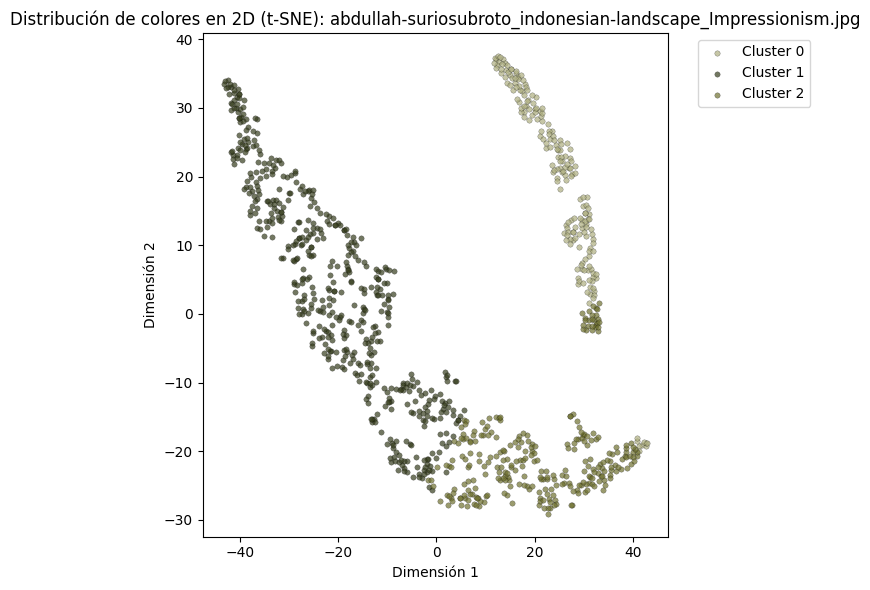

In [24]:
# Definir función para aplicar t-SNE como técnica de reducción de la dimensionalidad de 3 a 2
def visualizar_tsne(pixeles, etiquetas, centroides, nombre_imagen, muestra_max=1000, semilla=42, ax=None):
    """
    Proyecta los píxeles (originalmente en 3D: R,G,B) a un espacio de 2 dimensiones usando t-SNE, para visualizar qué tan separados y
    compactos quedaron los clusters de color encontrados por K-Means.
    """
    n_pixeles = len(pixeles)

    # Seleccionar muestra aleatoria si el número de píxeles es superior al de la muestra 
    if n_pixeles > muestra_max:
        indices = np.random.RandomState(semilla).choice(n_pixeles, muestra_max, replace=False)
        pixeles_muestra = pixeles[indices]
        etiquetas_muestra = etiquetas[indices]
    else:
        pixeles_muestra = pixeles
        etiquetas_muestra = etiquetas

    # Definir el hiperparámetro de t-SNE    
    perplexity = min(30, max(5, len(pixeles_muestra) // 10))

    # Enternar t-SNE
    tsne = TSNE(n_components=2, random_state=semilla, perplexity=perplexity, init="pca")
    proyeccion = tsne.fit_transform(pixeles_muestra)

    # Solo crea una figura propia si no recibió un eje externo
    crear_figura_propia = ax is None
    if crear_figura_propia:
        fig, ax = plt.subplots(figsize=(7, 6))

    # Gráficar un punto por píxel 
    for etiqueta in np.unique(etiquetas_muestra):
        mask = etiquetas_muestra == etiqueta
        color_cluster = centroides[etiqueta]
        ax.scatter(
            proyeccion[mask, 0], proyeccion[mask, 1],
            c=[color_cluster], label=f"Cluster {etiqueta}",
            s=15, alpha=0.7, edgecolors="k", linewidths=0.2
        )

    ax.set_title(f"Distribución de colores en 2D (t-SNE): {nombre_imagen}")
    ax.set_xlabel("Dimensión 1")
    ax.set_ylabel("Dimensión 2")
    ax.legend(bbox_to_anchor=(1.05, 1), loc="upper left")
    
    if crear_figura_propia:
        plt.tight_layout()
        plt.show()

# Prueba con la primera imagen
visualizar_tsne(
    pixeles=pixeles_imagen[0],
    etiquetas=resultado["etiquetas"],
    centroides=resultado["modelo"].cluster_centers_,
    nombre_imagen=resultado["nombre"]
)

### 5. Evidencia del desempeño del método construido mostrando la paleta generada

Ahora vamos a hacer el análisis para 6 imágenes, excluyendo la que usamos para la prueba :


índices seleccionados [6 4 8 9 7 1]
6:aleksandra-ekster_still-life-1910_Art_Nouveau_Modern.jpg
4:akseli-gallen-kallela_mt-donia-sabuk-1909_Expressionism.jpg
8:andrea-mantegna_the-house-of-ludovico-gonzaga-bridegroom-decorated-wall-and-his-son-1475_Early_Renaissance.jpg
9:walasse-ting_gauguin-ting-1976_Action_painting.jpg
7:andrea-del-sarto_piet-with-saints-1524_High_Renaissance.jpg
1:abraham-manievich_flowers-vase-on-a-hamper_Impressionism.jpg.jpg


## <span style='color:blue'>aleksandra-ekster_still-life-1910_Art_Nouveau_Modern.jpg</span>

Imagen: aleksandra-ekster_still-life-1910_Art_Nouveau_Modern.jpg

Resultados de los valores de k:
 k    inercia  silueta
 3 389.971649 0.469640
 4 290.959534 0.473735
 5 223.862961 0.428374
 6 189.266815 0.387988
 7 163.625290 0.396886
 8 147.442429 0.364455
 9 134.610550 0.372231
10 123.088806 0.368885

Mejor k: 4
Coeficiente de silueta: 0.474
Colores de la paleta:['#473B3E', '#7B6960', '#C9B095', '#B1513A']


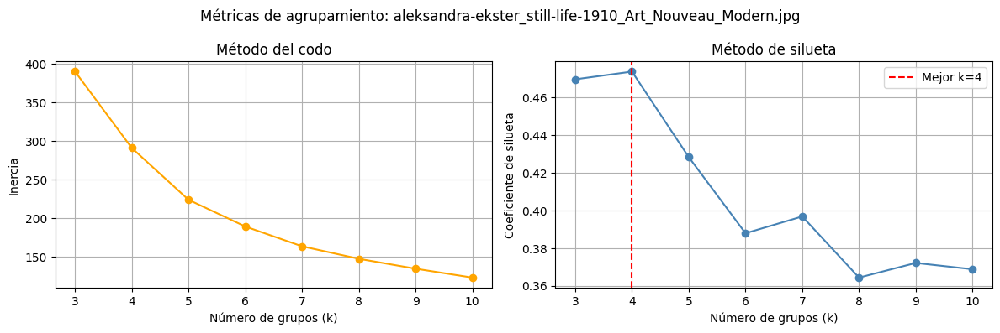

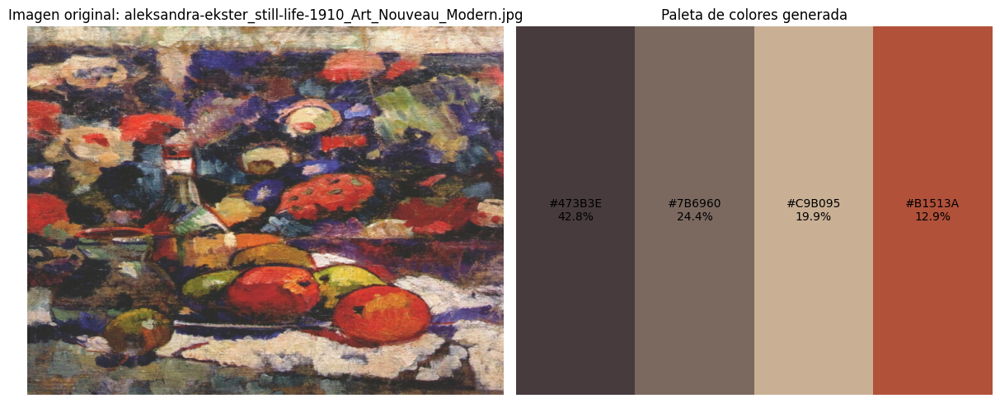

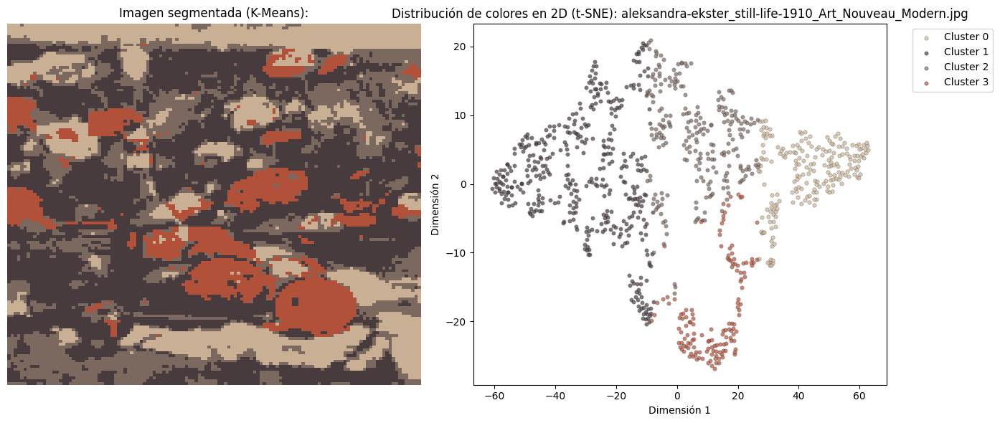

## <span style='color:blue'>akseli-gallen-kallela_mt-donia-sabuk-1909_Expressionism.jpg</span>

Imagen: akseli-gallen-kallela_mt-donia-sabuk-1909_Expressionism.jpg

Resultados de los valores de k:
 k    inercia  silueta
 3 490.424713 0.454606
 4 359.512299 0.492086
 5 279.168060 0.451864
 6 216.387543 0.440906
 7 180.327835 0.457976
 8 159.660904 0.459555
 9 144.371826 0.445902
10 131.780045 0.414484

Mejor k: 4
Coeficiente de silueta: 0.492
Colores de la paleta:['#C8C0B4', '#455E41', '#8D774A', '#65799B']


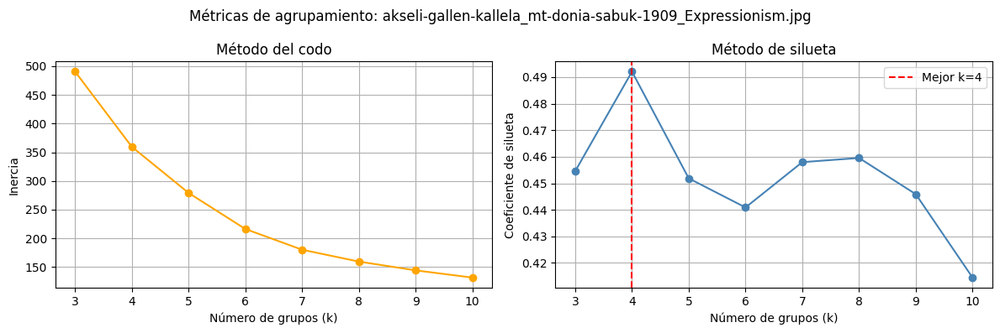

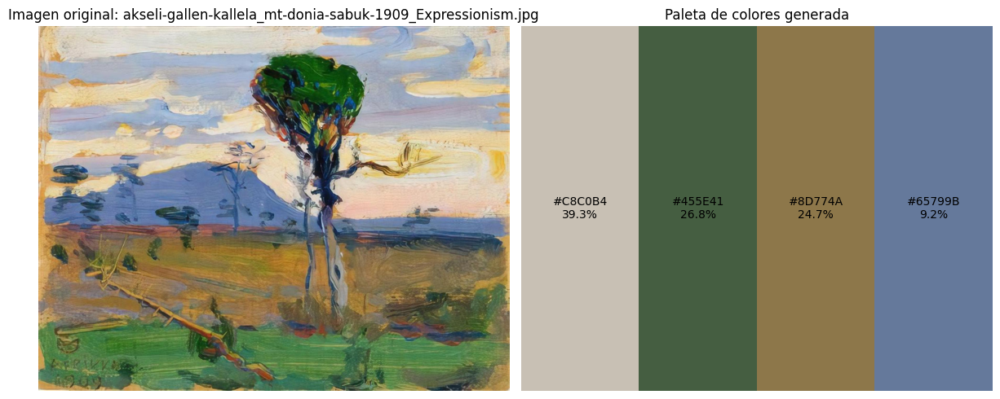

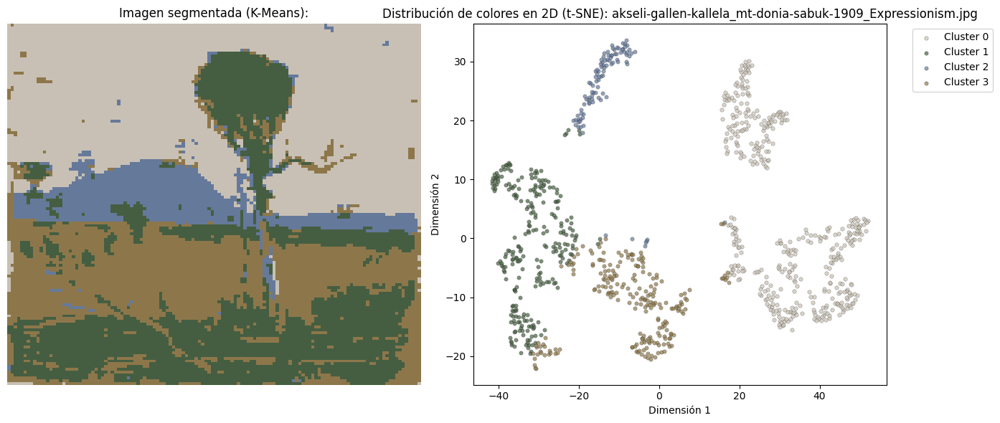

## <span style='color:blue'>andrea-mantegna_the-house-of-ludovico-gonzaga-bridegroom-decorated-wall-and-his-son-1475_Early_Renaissance.jpg</span>

Imagen: andrea-mantegna_the-house-of-ludovico-gonzaga-bridegroom-decorated-wall-and-his-son-1475_Early_Renaissance.jpg

Resultados de los valores de k:
 k    inercia  silueta
 3 722.050293 0.450259
 4 531.409485 0.422963
 5 413.209930 0.438143
 6 345.034698 0.402637
 7 297.750366 0.379183
 8 264.130798 0.353387
 9 232.027466 0.365616
10 210.882858 0.369542

Mejor k: 3
Coeficiente de silueta: 0.450
Colores de la paleta:['#242B32', '#78776E', '#C1C1B7']


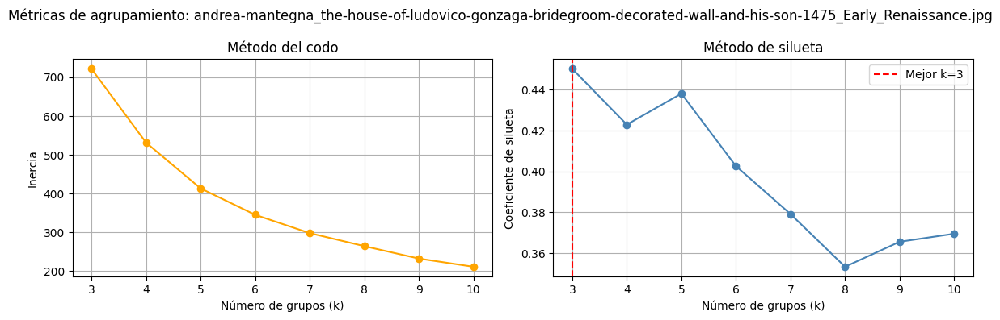

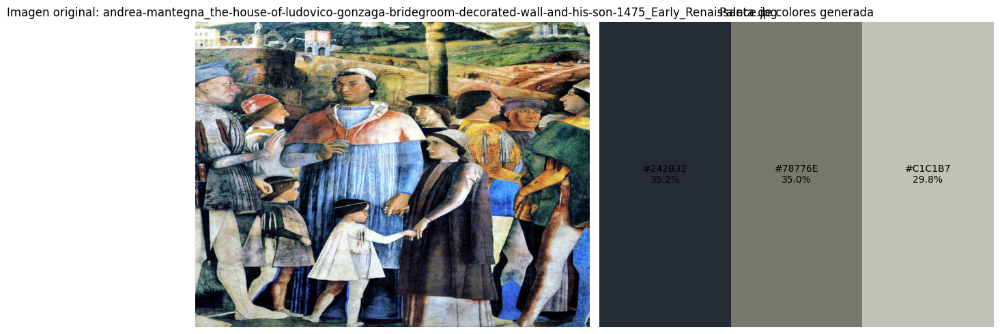

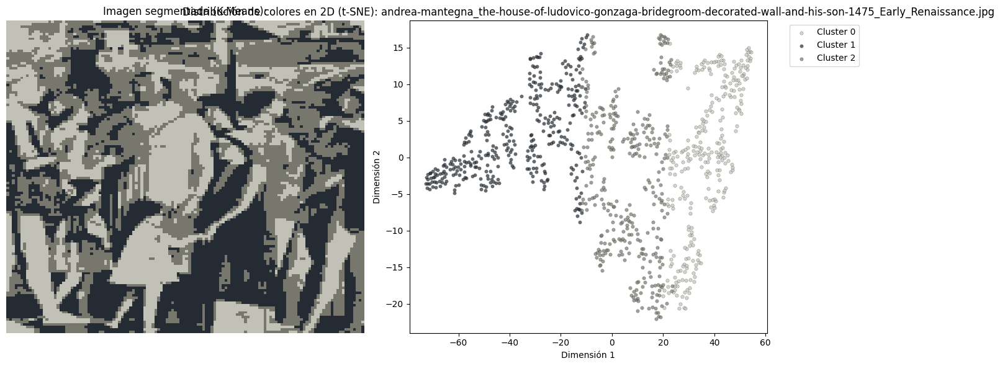

## <span style='color:blue'>walasse-ting_gauguin-ting-1976_Action_painting.jpg</span>

Imagen: walasse-ting_gauguin-ting-1976_Action_painting.jpg

Resultados de los valores de k:
 k     inercia  silueta
 3 1148.710205 0.398969
 4  783.681641 0.469293
 5  576.314209 0.498118
 6  470.833710 0.512304
 7  405.614380 0.517698
 8  347.397247 0.503060
 9  309.519196 0.502912
10  278.204041 0.493886

Mejor k: 7
Coeficiente de silueta: 0.518
Colores de la paleta:['#7E2D1E', '#DD513C', '#0D0D09', '#8A5F61', '#338D33', '#C6C643', '#2A7B92']


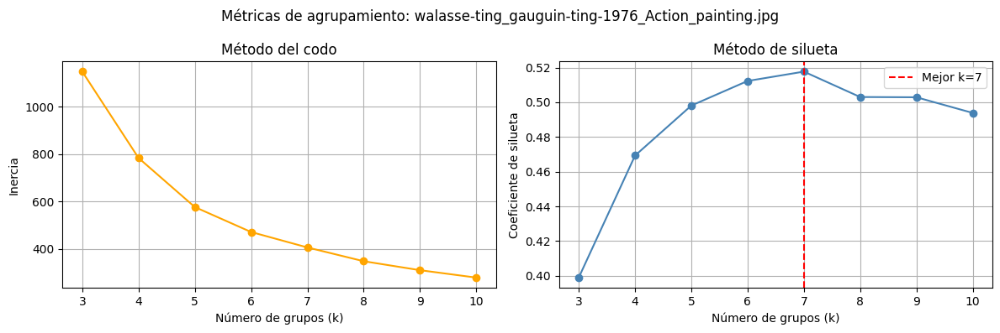

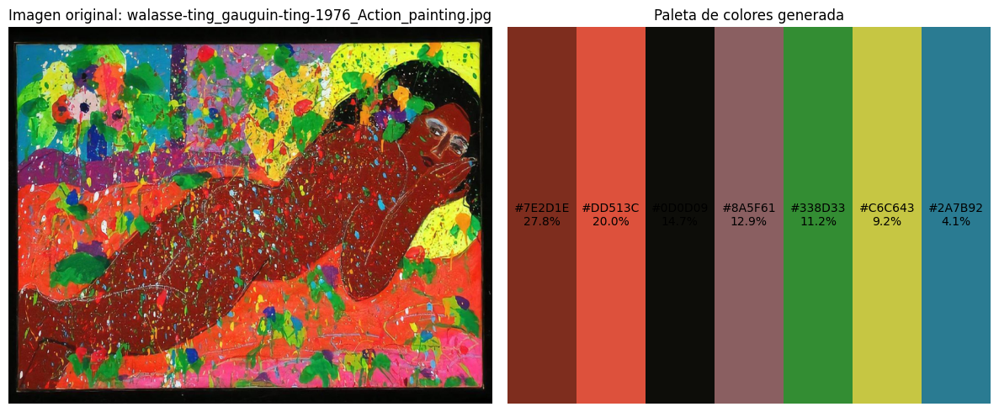

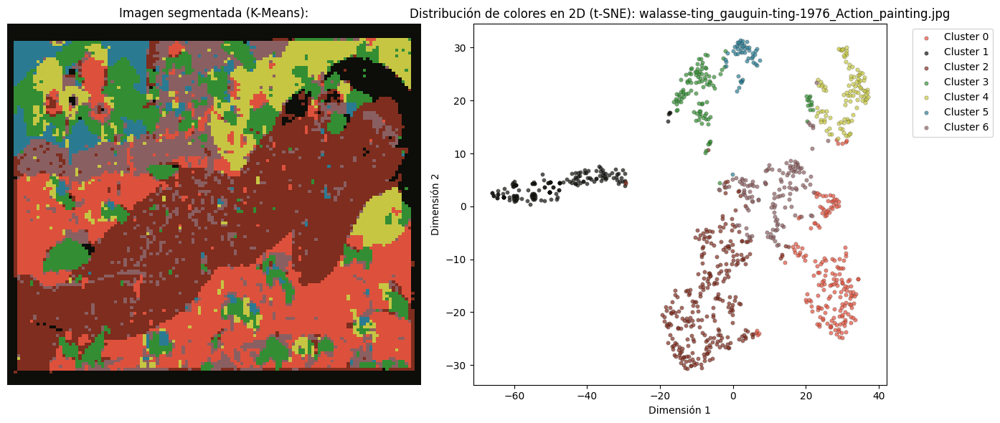

## <span style='color:blue'>andrea-del-sarto_piet-with-saints-1524_High_Renaissance.jpg</span>

Imagen: andrea-del-sarto_piet-with-saints-1524_High_Renaissance.jpg

Resultados de los valores de k:
 k    inercia  silueta
 3 506.707733 0.528876
 4 355.845032 0.431030
 5 266.029663 0.452968
 6 211.203720 0.443283
 7 172.882324 0.435846
 8 145.427948 0.451118
 9 122.453873 0.430737
10 109.778107 0.412860

Mejor k: 3
Coeficiente de silueta: 0.529
Colores de la paleta:['#352119', '#836D5C', '#C0B7B1']


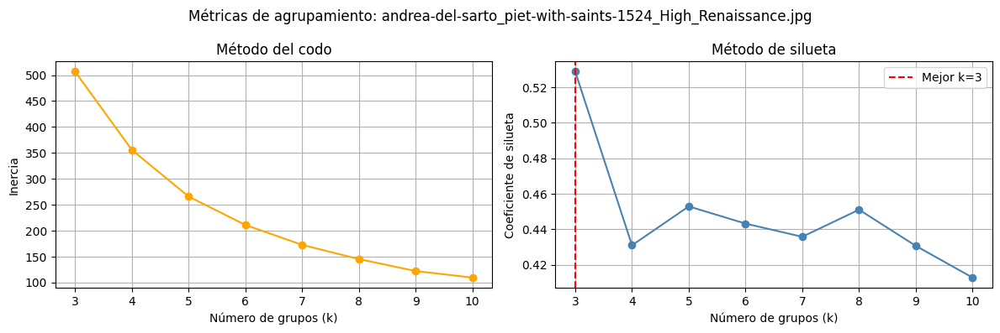

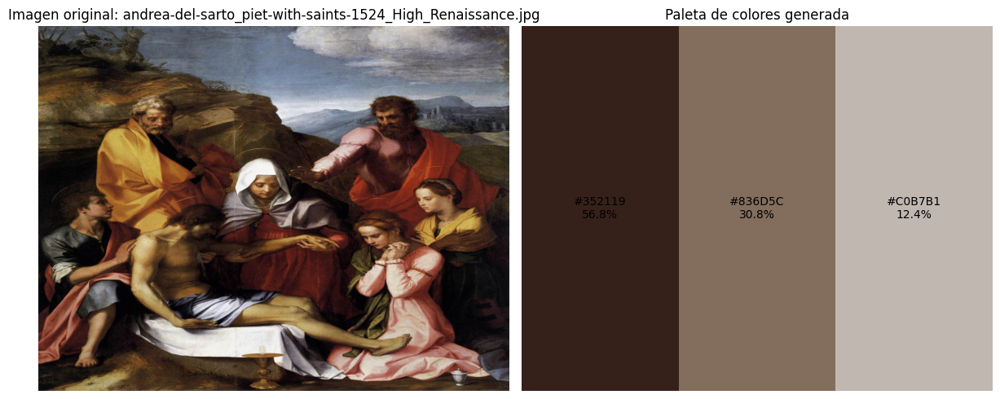

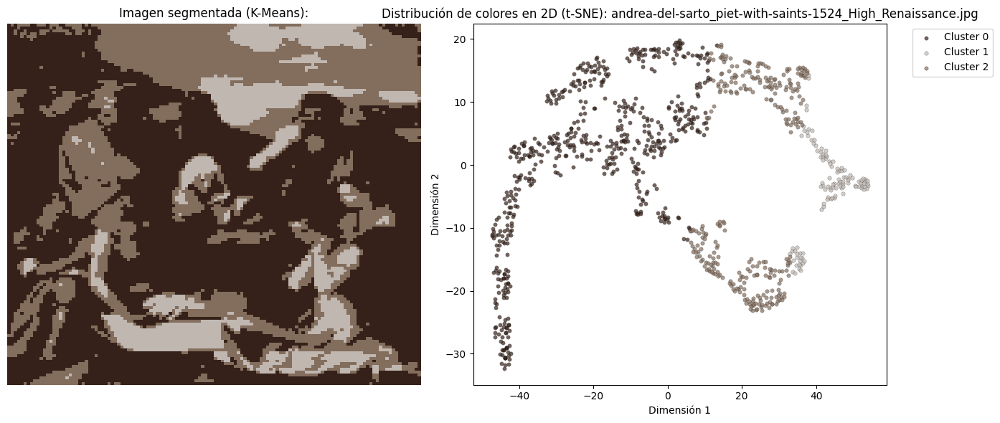

## <span style='color:blue'>abraham-manievich_flowers-vase-on-a-hamper_Impressionism.jpg.jpg</span>

Imagen: abraham-manievich_flowers-vase-on-a-hamper_Impressionism.jpg.jpg

Resultados de los valores de k:
 k    inercia  silueta
 3 264.630249 0.428962
 4 184.349487 0.482137
 5 140.006287 0.468983
 6 115.128410 0.480051
 7  92.950569 0.433173
 8  83.738686 0.405702
 9  75.743660 0.403882
10  70.158669 0.404724

Mejor k: 4
Coeficiente de silueta: 0.482
Colores de la paleta:['#898E7A', '#B1B09D', '#575B4D', '#A68D45']


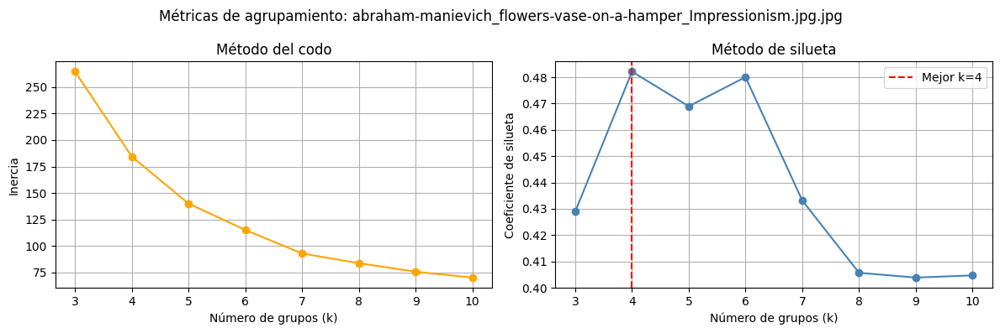

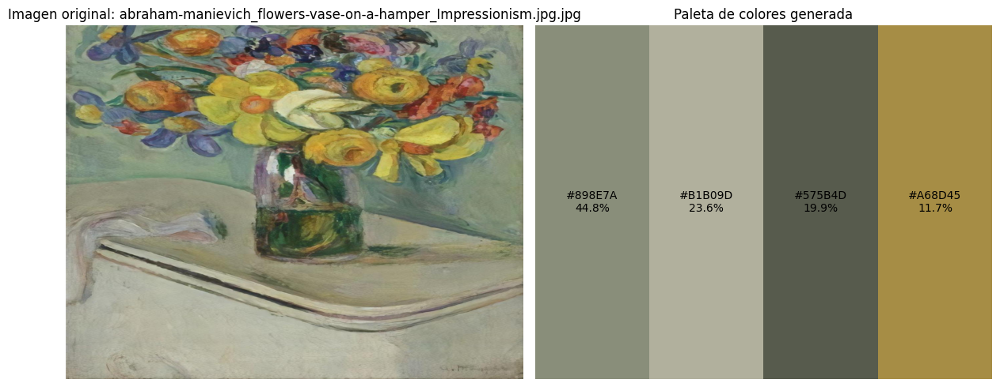

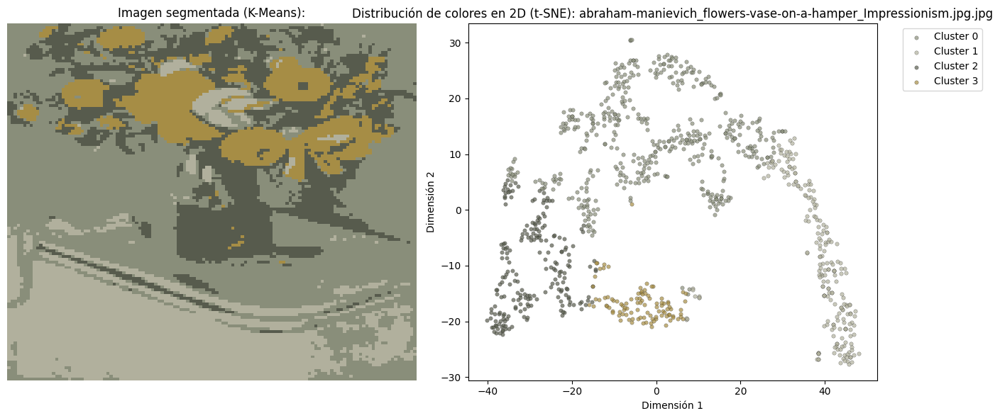

In [25]:
rng= np.random.default_rng(42)
indice_excluido=0
#Creamos el arreglo con  todos los índices de las imágenes
todos_los_indices=np.arange(len(pixeles_imagen))
#Elinamos la imagen que ya fue utilizada 
indices_disponibles=np.setdiff1d(todos_los_indices,[indice_excluido])
#Seleccionalos las 6 imágenes sin repetir: 
indices_seleccionados=rng.choice(indices_disponibles, size=6, replace=False)
print("índices seleccionados", indices_seleccionados)

for indice in indices_seleccionados:
    print(f"{indice}:{nombres[indice]}")
    
#Para guardar los resultados:
resultados_finales={}

for indice in indices_seleccionados:
    nombre=nombres[indice]
    pixeles=pixeles_imagen[indice]

    #Título en azul con el nombre de la imagen antes de iniciar su análisis
    display(Markdown(f"## <span style='color:blue'>{nombre}</span>"))

    #Ejecutamos la función k-means sobre la imagen actual
    resultado = analizar_imagen_kmeans(pixeles,nombre)
    resultados_k=resultado["resultados"]
    modelo=resultado["modelo"]
    etiquetas=resultado["etiquetas"]
    colores=resultado["colores"]
    porcentajes=resultado["porcentajes"]
    colores_hex=resultado["colores_hex"]
    #Obtenemos el modelo k_means con el mejor valor de k 
    mejor_modelo=mejor_numero_cluster(resultados_k)

    print(f"Imagen: {nombre}")
    print("\nResultados de los valores de k:")
    print(resultados_k[["k","inercia","silueta"]].to_string(index=False))
    print(f"\nMejor k: {modelo.n_clusters}")
    print(f"Coeficiente de silueta: {mejor_modelo['silueta']:.3f}")
    print(f"Colores de la paleta:{colores_hex}")
    graficar_metricas(resultados_k, nombre)

    #Para imprimir la figura original y su paleta
    fig, axes=plt.subplots(1,2, figsize=(12,5))
    axes[0].imshow(imagenes[indice],aspect="auto")
    axes[0].axis("off")
    axes[0].set_title(f"Imagen original: {nombre}")
    for posicion,(color,porcentaje,color_hex) in enumerate(zip(colores, porcentajes, colores_hex)):
        axes[1].bar(posicion,1,color=color/255, width=1)
        axes[1].text(posicion, 0.5, f"{color_hex}\n{porcentaje:.1f}%",ha="center", va="center")
    axes[1].set_xlim(-0.5, len(colores)-0.5)
    axes[1].set_ylim(0,1)
    axes[1].axis("off")
    axes[1].set_title("Paleta de colores generada")
    plt.tight_layout()
    plt.show()

    #Para imprimir la imagen segmentada junto al t-SNE
    imagen_segmentada=reconstruir_imagen_segmentada(etiquetas, modelo.cluster_centers_)

    fig, axes=plt.subplots(1,2, figsize=(14,6))
    axes[0].imshow(imagen_segmentada,aspect="auto")
    axes[0].axis("off")
    axes[0].set_title(f"Imagen segmentada (K-Means):")

    visualizar_tsne(pixeles=pixeles, etiquetas=etiquetas, centroides=modelo.cluster_centers_, nombre_imagen=nombre, ax=axes[1])

    plt.tight_layout()
    plt.show()

    resultados_finales[indice]={
        "nombre": nombre,
        "resultado_k":resultado,
        "modelo":modelo, 
        "etiquetas": etiquetas,
        "colores": colores, 
        "porcentajes": porcentajes, 
        "colores_hex":colores_hex
    }
    

    

## CONCLUSIONES

A partir del análisis realizado sobre las imágenes seleccionadas, se observa que K-Means, validado mediante el coeficiente de silueta, permite generar paletas de colores estables, reproducibles y ajustadas a la complejidad de cada obra: estilos con transiciones de color graduales (por ejemplo, impresionismo) tienden a seleccionar valores de k más bajos, mientras que estilos con colores más definidos y contrastantes producen particiones más finas. La comparación exploratoria con MeanShift evidenció que este algoritmo puede identificar un número distinto de colores dominantes según el ancho de banda estimado automáticamente a partir de la muestra de píxeles, sin que exista un criterio de validación cuantitativo equivalente al coeficiente de silueta, lo que confirma a K-Means como el algoritmo más adecuado para esta tarea al ofrecer control explícito, menor costo computacional y mayor estabilidad en los resultados.

La reconstrucción de las imágenes segmentadas permitió validar cualitativamente que los centroides encontrados por K-Means representan adecuadamente las regiones de color dominantes de cada obra, mientras que las proyecciones t-SNE mostraron que los clústeres identificados son, en general, compactos y separables en el espacio bidimensional, respaldando la calidad del agrupamiento obtenido.

Finalmente, el uso de un pipeline reutilizable (redimensionamiento, aplanamiento y normalización de píxeles) y de una selección aleatoria del conjunto de imágenes analizadas demuestra que el método propuesto generaliza adecuadamente a distintos estilos artísticos, sin depender de una muestra fija o de ajustes manuales por imagen.